In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
dataset = pd.read_csv('Mall_Customersnew.csv')


In [3]:
dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [4]:
X = dataset.iloc[:, 3:4].values

In [5]:
X

array([[15],
       [15],
       [16],
       [16],
       [17],
       [17],
       [18],
       [18],
       [19],
       [19],
       [19],
       [19],
       [20],
       [20],
       [20],
       [20],
       [21],
       [21],
       [23],
       [23],
       [24],
       [24],
       [25],
       [25],
       [28],
       [28],
       [28],
       [28],
       [29],
       [29],
       [30],
       [30],
       [33],
       [33],
       [33],
       [33],
       [34],
       [34],
       [37],
       [37],
       [38],
       [38],
       [39],
       [39],
       [39],
       [39],
       [40],
       [40],
       [40]])

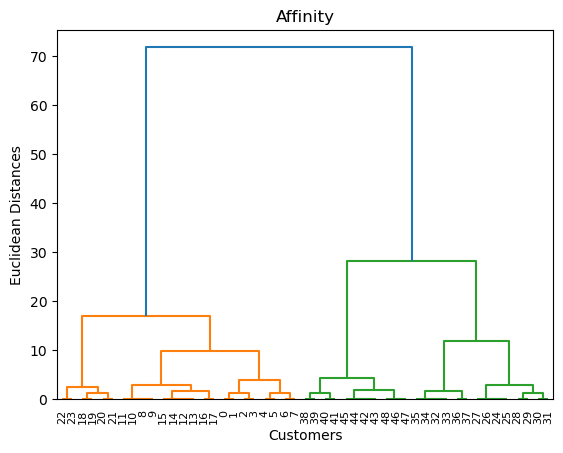

In [6]:
import scipy.cluster.hierarchy as sch




linkage_matrix = sch.linkage(X, method="ward")


dendrogram = sch.dendrogram(linkage_matrix)

plt.title("Affinity")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distances")

plt.show()

In [7]:
 from sklearn.cluster import AffinityPropagation

In [8]:

#aff = AffinityPropagation(random_state=5)
#y_aff=aff.fit_predict(X)

aff = AffinityPropagation(
    damping=0.7,
    max_iter=500,
    convergence_iter=20,
    preference=-50,
    affinity="euclidean",
    random_state=42
)
y_aff=aff.fit_predict(X)

#from sklearn.cluster import AgglomerativeClustering
#clusmodel = AgglomerativeClustering(n_clusters=5)
#label = clusmodel.fit_predict(X)
supervised=pd.DataFrame(dataset)

In [9]:
supervised['Cluster_group']=y_aff

In [10]:
y_aff

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4,
       4, 4, 4, 4, 4])

In [11]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0
5,6,Female,22,17,76,0
6,7,Female,35,18,6,0
7,8,Female,23,18,94,0
8,9,Male,64,19,3,0
9,10,Female,30,19,72,0


C:\Users\bkmad\anaconda3\Lib\site-packages\seaborn\regression.py:598: UserWarning: legend_out is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


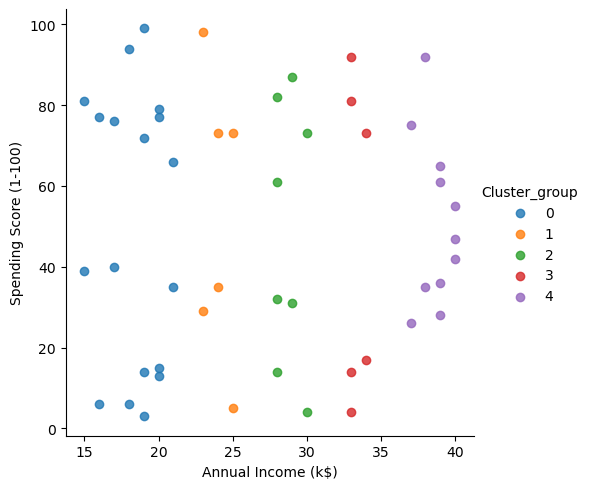

In [12]:
import seaborn as sns
facet = sns.lmplot(data=supervised, x=supervised.columns[3], y=supervised.columns[4], hue=supervised.columns[5], 
                   fit_reg=False, legend=True, legend_out=True)

In [ ]:
import seaborn as sns
facet = sns.lmplot(data=supervised, x=supervised.columns[3], y=supervised.columns[4], hue=supervised.columns[5],
                   fit_reg=False,legend_out=True)

In [ ]:
#!pip install seaborn